In [1]:
!pip install -q "transformers==4.40.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 80.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.40.0 which is incompatible.


# Cell 1 — load the cached embeddings from the attached notebook output:

In [2]:
import numpy as np, glob
if not hasattr(np, "trapz"):            # NumPy 2.0 renamed trapz -> trapezoid
    np.trapz = np.trapezoid

NPZ = glob.glob("/kaggle/input/notebooks/mdnomanbiswassibly/conch-set-up/pannuke_fold1_conch.npz", recursive=True)[0]
d = np.load(NPZ, allow_pickle=True)
emb_probe    = d["emb_probe"].astype(np.float32)     # (N,512) pre-projection -> probe + geometry
emb_contrast = d["emb_contrast"].astype(np.float32)  # (N,512) normalized -> (kept for completeness)
labels       = d["labels"].astype(int)
img_idx      = d["img_idx"].astype(int)
tissues      = np.asarray(d["tissues"])              # per-nucleus organ string -> FREE organ shift
CLASS_NAMES  = ["Neoplastic","Inflammatory","Connective","Dead","Epithelial"]
N_CLS = 5
print("N =", len(labels), "| class counts:", np.bincount(labels))

def grouped_split(img_idx, fracs=(0.60, 0.15, 0.25), seed=0):
    """Whole images go entirely to train OR val OR test (no leakage)."""
    rng = np.random.RandomState(seed)
    imgs = np.unique(img_idx); rng.shuffle(imgs)
    n = len(imgs); a = int(fracs[0]*n); b = int((fracs[0]+fracs[1])*n)
    s_tr, s_va, s_te = set(imgs[:a]), set(imgs[a:b]), set(imgs[b:])
    inset = lambda s: np.fromiter((i in s for i in img_idx), bool, len(img_idx))
    return inset(s_tr), inset(s_va), inset(s_te)

tr, va, te = grouped_split(img_idx)
print("train/val/test nuclei:", tr.sum(), va.sum(), te.sum())

N = 51365 | class counts: [21276  8863 13368   790  7068]
train/val/test nuclei: 31187 7495 12683


# Cell 2 — zero-shot text head (needs CONCH loaded for the text encoder).

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, classification_report, f1_score

scaler = StandardScaler().fit(emb_probe[tr])
Xtr, Xva, Xte = (scaler.transform(emb_probe[m]) for m in (tr, va, te))
ytr, yva, yte = labels[tr], labels[va], labels[te]

clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, ytr)
pred_te = clf.predict(Xte)
print("Balanced acc (test):", round(balanced_accuracy_score(yte, pred_te), 3))
print(classification_report(yte, pred_te, target_names=CLASS_NAMES, digits=3))

def bootstrap_ci(metric_fn, y, p, n=1000, seed=0):
    rng = np.random.RandomState(seed); vals = []
    idx = np.arange(len(y))
    for _ in range(n):
        b = rng.choice(idx, len(idx), replace=True)
        vals.append(metric_fn(y[b], p[b]))
    lo, hi = np.percentile(vals, [2.5, 97.5]); return float(np.mean(vals)), float(lo), float(hi)

m, lo, hi = bootstrap_ci(balanced_accuracy_score, yte, pred_te)
print(f"Balanced acc 95% CI: {m:.3f} [{lo:.3f}, {hi:.3f}]")

Balanced acc (test): 0.734
              precision    recall  f1-score   support

  Neoplastic      0.843     0.757     0.797      5504
Inflammatory      0.655     0.749     0.699      2023
  Connective      0.706     0.662     0.684      3242
        Dead      0.446     0.801     0.573       191
  Epithelial      0.589     0.699     0.640      1723

    accuracy                          0.724     12683
   macro avg      0.648     0.734     0.679     12683
weighted avg      0.738     0.724     0.728     12683

Balanced acc 95% CI: 0.734 [0.720, 0.747]


# Cell 3 — Phase 2: train the calibrated probe + temperature scaling + ECE:

In [4]:
import torch
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def ece(probs, y, n_bins=15):
    conf = probs.max(1); pred = probs.argmax(1); correct = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins+1); e = 0.0
    for i in range(n_bins):
        msk = (conf > bins[i]) & (conf <= bins[i+1])
        if msk.sum(): e += abs(correct[msk].mean() - conf[msk].mean()) * msk.sum()
    return e / len(y)

def fit_temperature(logits, y, iters=100):
    T = torch.nn.Parameter(torch.ones(1))
    L = torch.tensor(logits).float(); Y = torch.tensor(y).long()
    opt = torch.optim.LBFGS([T], lr=0.01, max_iter=iters)
    def closure():
        opt.zero_grad(); loss = torch.nn.functional.cross_entropy(L/T, Y); loss.backward(); return loss
    opt.step(closure); return float(T.item())

logit_va, logit_te = clf.decision_function(Xva), clf.decision_function(Xte)
T = fit_temperature(logit_va, yva)            # <<< fit on VAL, report on TEST
print("Temperature (val-fit):", round(T, 3))

p_before, p_after = softmax(logit_te), softmax(logit_te / T)
print("ECE test  before:", round(ece(p_before, yte), 4), "| after:", round(ece(p_after, yte), 4))

def risk_coverage(conf, correct):
    order = np.argsort(-conf); c = correct[order].astype(float)
    cov = np.arange(1, len(c)+1) / len(c)
    risk = 1 - np.cumsum(c) / np.arange(1, len(c)+1)
    return cov, risk, float(np.trapz(risk, cov))

conf = p_after.max(1); correct = (p_after.argmax(1) == yte)
cov, risk, aurc = risk_coverage(conf, correct)
print("AURC:", round(aurc, 4))
for q in (0.7, 0.8, 0.9, 1.0):
    k = int(q*len(correct)); print(f"  acc @ {int(q*100)}% coverage:", round(correct[np.argsort(-conf)][:k].mean(), 3))
# T2 baselines: same risk-coverage but ranked by MSP (uncalibrated) and by energy
energy = -torch.logsumexp(torch.tensor(logit_te).float(), 1).numpy()  # higher = less confident
for name, score in [("MSP_uncal", p_before.max(1)), ("neg_energy", -energy)]:
    _, _, a = risk_coverage(score, correct); print(f"  AURC ({name}):", round(a, 4))

Temperature (val-fit): 1.082
ECE test  before: 0.0197 | after: 0.0174
AURC: 0.1458
  acc @ 70% coverage: 0.822
  acc @ 80% coverage: 0.79
  acc @ 90% coverage: 0.758
  acc @ 100% coverage: 0.724
  AURC (MSP_uncal): 0.1458
  AURC (neg_energy): 0.184


# Cell 4 — the risk-coverage curve (Gate 2's money figure):

In [5]:
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors

# ---- epistemic: class means + tied precision on TRAIN ----
mus = np.stack([Xtr[ytr == c].mean(0) for c in range(N_CLS)]).astype(np.float32)  # (5,512)
resid = (Xtr - mus[ytr]).astype(np.float32)
P = LedoitWolf().fit(resid).precision_.astype(np.float32)                          # (512,512)

def maha_min_dist(X):
    """Min Mahalanobis distance to any class Gaussian. Larger = more off-manifold (epistemic)."""
    out = np.empty((len(X), N_CLS), np.float32)
    for c in range(N_CLS):
        D = X - mus[c]; out[:, c] = np.einsum("nd,dk,nk->n", D, P, D)
    return out.min(1)

# ---- aleatoric: kNN label disagreement vs predicted class on TRAIN ----
K = 20
nn = NearestNeighbors(n_neighbors=K).fit(Xtr)
def knn_overlap(X, pred):
    _, idx = nn.kneighbors(X, n_neighbors=K)
    same = (ytr[idx] == pred[:, None]).mean(1)
    return 1.0 - same  # larger = locally confusable (aleatoric)

epi_te = maha_min_dist(Xte)
ale_te = knn_overlap(Xte, p_after.argmax(1))

# ---- G-B check: do the two quantities separate correct from incorrect? ----
ok = (p_after.argmax(1) == yte)
print("epistemic  (manifold dist)  correct vs wrong:", round(epi_te[ok].mean(),3), "vs", round(epi_te[~ok].mean(),3))
print("aleatoric  (local overlap)  correct vs wrong:", round(ale_te[ok].mean(),3), "vs", round(ale_te[~ok].mean(),3))
# F3: scatter (ale_te, epi_te) coloured by {correct / abstained=low-conf / wrong}; UMAP of Xte by class.

epistemic  (manifold dist)  correct vs wrong: 303.675 vs 317.788
aleatoric  (local overlap)  correct vs wrong: 0.358 vs 0.626


In [6]:
def per_class_geometry(mask, name):
    X = scaler.transform(emb_probe[mask]); y = labels[mask]
    pr = clf.predict(X); epi = maha_min_dist(X); ale = knn_overlap(X, pr)
    print(f"\n[{name}]  class :  aleatoric(overlap)   epistemic(maha)   (mean ± boot95)")
    for c in range(N_CLS):
        m = y == c
        if m.sum() < 5: print(f"  {CLASS_NAMES[c]:13s}:  n<5 (skip)"); continue
        a_m, a_lo, a_hi = bootstrap_ci(lambda yy, pp: pp.mean(), y[m], ale[m])
        e_m, e_lo, e_hi = bootstrap_ci(lambda yy, pp: pp.mean(), y[m], epi[m])
        print(f"  {CLASS_NAMES[c]:13s}:  {a_m:.3f} [{a_lo:.3f},{a_hi:.3f}]   {e_m:.3f} [{e_lo:.3f},{e_hi:.3f}]")

per_class_geometry(te, "TEST")     # Dead should be high overlap / low maha
per_class_geometry(va, "VAL")      # G-A: pattern must REPLICATE on val
# F4: grouped bars (overlap vs maha) per class, with CIs. Kill if Dead not separably aleatoric.


[TEST]  class :  aleatoric(overlap)   epistemic(maha)   (mean ± boot95)
  Neoplastic   :  0.373 [0.366,0.380]   294.034 [291.009,297.196]
  Inflammatory :  0.442 [0.431,0.453]   299.937 [295.116,304.611]
  Connective   :  0.511 [0.502,0.519]   331.419 [326.827,335.857]
  Dead         :  0.518 [0.479,0.555]   577.619 [551.153,607.016]
  Epithelial   :  0.449 [0.435,0.463]   285.225 [279.691,290.788]

[VAL]  class :  aleatoric(overlap)   epistemic(maha)   (mean ± boot95)
  Neoplastic   :  0.384 [0.375,0.393]   290.242 [286.647,294.069]
  Inflammatory :  0.438 [0.424,0.451]   343.560 [335.398,351.387]
  Connective   :  0.500 [0.488,0.511]   313.990 [309.087,318.694]
  Dead         :  0.383 [0.292,0.476]   470.948 [428.212,514.550]
  Epithelial   :  0.396 [0.379,0.413]   264.765 [258.558,271.530]


In [7]:
from sklearn.metrics import roc_auc_score

def loco_openset(held):
    """Train on the other 4 classes; score held-out TEST cells as 'unknown'."""
    keep = labels != held
    tr_k = tr & keep
    sc = StandardScaler().fit(emb_probe[tr_k])
    Xk = sc.transform(emb_probe[tr_k]); yk = labels[tr_k]
    cls = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xk, yk)
    classes = np.unique(yk)
    mu = np.stack([Xk[yk == c].mean(0) for c in classes]).astype(np.float32)
    Pk = LedoitWolf().fit((Xk - mu[np.searchsorted(classes, yk)]).astype(np.float32)).precision_.astype(np.float32)

    Xte_all = sc.transform(emb_probe[te]); is_unknown = (labels[te] == held).astype(int)
    lg = cls.decision_function(Xte_all)
    msp    = 1 - softmax(lg).max(1)                                   # higher = unknown
    energy = -torch.logsumexp(torch.tensor(lg).float(), 1).numpy()    # higher = unknown
    maha   = np.min(np.stack([np.einsum("nd,dk,nk->n", Xte_all-mu[i], Pk, Xte_all-mu[i])
                              for i in range(len(classes))], 1), 1)    # higher = unknown
    return {s: roc_auc_score(is_unknown, v) for s, v in
            [("MSP", msp), ("energy", energy), ("maha", maha)]}

rows = {}
for h in range(N_CLS):
    rows[CLASS_NAMES[h]] = loco_openset(h)
    print(f"{CLASS_NAMES[h]:13s}", {k: round(v,3) for k, v in rows[CLASS_NAMES[h]].items()})

# G-D / F5: per-class open-set AUROC (best of 3) vs per-class epistemic score from S4.
# Expect: detectable-as-novel  <->  high epistemic, low aleatoric. Dead = the explained exception.

Neoplastic    {'MSP': np.float64(0.623), 'energy': np.float64(0.596), 'maha': np.float64(0.565)}
Inflammatory  {'MSP': np.float64(0.572), 'energy': np.float64(0.692), 'maha': np.float64(0.574)}
Connective    {'MSP': np.float64(0.639), 'energy': np.float64(0.676), 'maha': np.float64(0.633)}
Dead          {'MSP': np.float64(0.602), 'energy': np.float64(0.371), 'maha': np.float64(0.933)}
Epithelial    {'MSP': np.float64(0.674), 'energy': np.float64(0.533), 'maha': np.float64(0.499)}


In [8]:
def oscr(unknown_score, correct_known, is_unknown):
    """Correct-Classification-Rate vs False-Positive-Rate area. Higher = better."""
    thr = np.unique(unknown_score)
    known = is_unknown == 0
    ccr, fpr = [], []
    for t in thr:
        accept = unknown_score <= t
        ccr.append((accept & known & correct_known).sum() / max(known.sum(), 1))
        fpr.append((accept & ~known).sum() / max((~known).sum(), 1))
    o = np.argsort(fpr); return float(np.trapz(np.array(ccr)[o], np.array(fpr)[o]))

In [9]:
def organ_shift(seed=0, n_test_organs=6):
    rng = np.random.RandomState(seed)
    organs = np.unique(tissues); rng.shuffle(organs)
    test_org = set(organs[:n_test_organs].tolist())
    o_te = np.fromiter((t in test_org for t in tissues), bool, len(tissues))
    o_tr = ~o_te
    sc = StandardScaler().fit(emb_probe[o_tr])
    cls = LogisticRegression(max_iter=2000, class_weight="balanced").fit(sc.transform(emb_probe[o_tr]), labels[o_tr])
    Xs = sc.transform(emb_probe[o_te]); ys = labels[o_te]
    ba = balanced_accuracy_score(ys, cls.predict(Xs))
    # geometry under organ shift: reuse the IN-DISTRIBUTION reference (mus, P, nn) from S3
    epi = maha_min_dist(scaler.transform(emb_probe[o_te])).mean()
    print(f"Organ-shift: held-out organs={sorted(test_org)}")
    print(f"  balanced acc (shift): {ba:.3f}  | mean manifold-dist: {epi:.3f}")
    return ba, epi
organ_shift()
# Compare against the in-distribution random-split balanced acc + mean epi_te from S3.

Organ-shift: held-out organs=['Bile-duct', 'Kidney', 'Lung', 'Skin', 'Testis', 'Uterus']
  balanced acc (shift): 0.412  | mean manifold-dist: 324.255


(np.float64(0.41164326998938794), np.float32(324.2553))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 89.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incom

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


meta.yaml:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/802M [00:00<?, ?B/s]

CONCH on cuda
USING:
  /kaggle/input/datasets/andrewmvd/cancer-inst-segmentation-and-classification/Part 1/Images/images.npy 
  /kaggle/input/datasets/andrewmvd/cancer-inst-segmentation-and-classification/Part 1/Masks/masks.npy
IMAGES: (2656, 256, 256, 3) MASKS: (2656, 256, 256, 6)


regen crops: 100%|██████████| 2656/2656 [02:02<00:00, 21.61it/s]


crops aligned: (51365, 64, 64, 3)

severity |     bal.acc      |       ECE        |      AURC        |    mean manifold-dist
----------------------------------------------------------------------------------------------
   0.00  | 0.734 ± 0.000 | 0.017 ± 0.000 | 0.146 ± 0.000 |   307.6 ±   0.0
   0.05  | 0.533 ± 0.008 | 0.184 ± 0.005 | 0.382 ± 0.003 |   803.3 ±   4.1
   0.10  | 0.388 ± 0.005 | 0.330 ± 0.003 | 0.593 ± 0.006 |  1491.0 ±   6.4
   0.20  | 0.268 ± 0.008 | 0.470 ± 0.006 | 0.745 ± 0.009 |  2686.5 ±  12.3
   0.35  | 0.228 ± 0.004 | 0.503 ± 0.005 | 0.764 ± 0.009 |  3606.3 ±  10.8


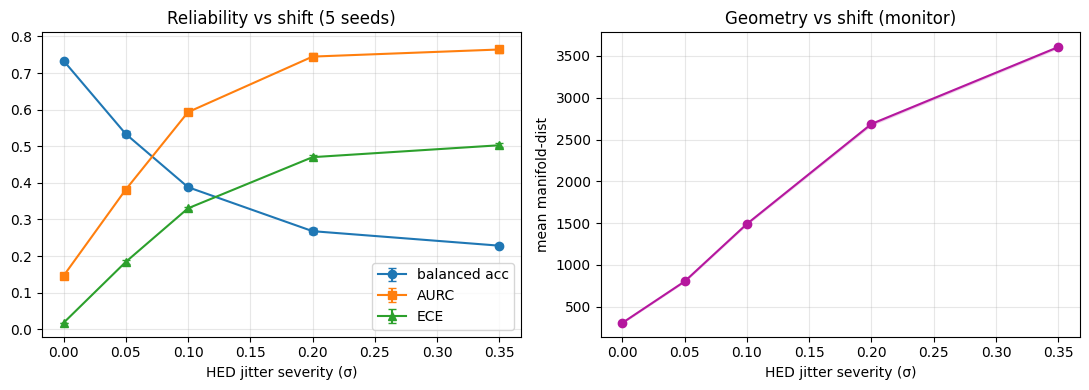

In [10]:
# ================= S6b — stain-corruption severity curve (multi-seed) =================
!GIT_TERMINAL_PROMPT=0 pip install -q "git+https://github.com/mahmoodlab/CONCH.git"
from conch.open_clip_custom import create_model_from_pretrained
import torch, glob, os, numpy as np
from PIL import Image; from tqdm import tqdm
from kaggle_secrets import UserSecretsClient
from skimage.color import rgb2hed, hed2rgb
from sklearn.metrics import balanced_accuracy_score

# --- CONCH (image encoder) ---
tok = UserSecretsClient().get_secret("HF token")     # must match your Kaggle secret name
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = create_model_from_pretrained(
    "conch_ViT-B-16", "hf_hub:MahmoodLab/conch", hf_auth_token=tok)
model = model.to(device).eval()
print("CONCH on", device)

# --- locate the Fold-1 raw arrays under your Part 1 path ---
PART1 = "/kaggle/input/datasets/andrewmvd/cancer-inst-segmentation-and-classification/Part 1"
def _find(name):
    hits = glob.glob(os.path.join(PART1, "**", name), recursive=True)
    if not hits: raise FileNotFoundError(f"{name} not found under {PART1}")
    return sorted(hits, key=len)[0]
imgs_npy, masks_npy = _find("Images/images.npy"), _find("Masks/masks.npy")
print("USING:\n ", imgs_npy, "\n ", masks_npy)
IMAGES = np.load(imgs_npy, mmap_mode="r"); MASKS = np.load(masks_npy, mmap_mode="r")
print("IMAGES:", IMAGES.shape, "MASKS:", MASKS.shape)

# --- regenerate crops in the SAME order as the cache (match CROP/MIN_VALID) ---
CROP, MIN_VALID = 64, 0.6
def nuclei_in_image(mask):
    out = []
    for c in range(5):
        ch = mask[:, :, c]
        for inst in np.unique(ch):
            if inst == 0: continue
            ys, xs = np.where(ch == inst); out.append((c, int(ys.mean()), int(xs.mean())))
    return out
def crop_patch(img, r, c, size=CROP):
    h = size//2; R, C = img.shape[:2]; r0,r1,c0,c1 = r-h,r+h,c-h,c+h
    pt,pl = max(0,-r0),max(0,-c0); pb,pr = max(0,r1-R),max(0,c1-C)
    r0,r1,c0,c1 = max(0,r0),min(R,r1),max(0,c0),min(C,c1)
    patch = np.pad(img[r0:r1,c0:c1], ((pt,pb),(pl,pr),(0,0)), "constant")
    return patch[:size,:size]

crops = []
for i in tqdm(range(len(IMAGES)), desc="regen crops"):
    img = np.asarray(IMAGES[i]).astype(np.uint8); m = np.asarray(MASKS[i])
    for cls, r, c in nuclei_in_image(m):
        h = CROP//2; vh = min(r+h,256)-max(r-h,0); vw = min(c+h,256)-max(c-h,0)
        if (vh*vw)/(CROP*CROP) < MIN_VALID: continue
        crops.append(crop_patch(img, r, c))
crops = np.stack(crops)
assert len(crops) == len(labels), f"order mismatch: {len(crops)} vs {len(labels)} — wrong fold attached?"
print("crops aligned:", crops.shape)

# --- HED stain jitter + re-embed (corrupt ONLY the test split) ---
def hed_jitter(img, sigma, rng):
    hed = rgb2hed(img/255.0)
    hed = hed*(1 + rng.uniform(-sigma, sigma, 3)) + rng.uniform(-sigma, sigma, 3)
    return np.clip(hed2rgb(hed)*255, 0, 255).astype(np.uint8)

@torch.inference_mode()
def embed_probe(batch):
    t = torch.stack([preprocess(Image.fromarray(p)) for p in batch]).to(device)
    return model.encode_image(t, proj_contrast=False, normalize=False).cpu().numpy()

# ---- metrics for one set of (possibly corrupted) crops, using FROZEN scaler/probe/T/geometry ----
def stain_metrics(crop_set):
    emb = np.concatenate([embed_probe(crop_set[s:s+256]) for s in range(0, len(crop_set), 256)])
    Xs  = scaler.transform(emb)                          # frozen scaler (S1)
    pa  = softmax(clf.decision_function(Xs) / T)         # frozen probe + T (S2)
    ba  = balanced_accuracy_score(yte, pa.argmax(1))
    e   = ece(pa, yte)
    _, _, a = risk_coverage(pa.max(1), pa.argmax(1) == yte)
    epi = float(maha_min_dist(Xs).mean())                # frozen geometry (S3)
    return (ba, e, a, epi)

# ---- STEP 0: multi-seed over the jitter randomness ----
te_crops = crops[te]
SEEDS = range(5)
sigmas_corrupt = [0.05, 0.10, 0.20, 0.35]
sigmas = [0.0] + sigmas_corrupt

# sigma=0 is deterministic (no jitter) -> embed once, std is 0 by definition
results_ms = {0.0: [stain_metrics(te_crops)]}
for sigma in sigmas_corrupt:
    results_ms[sigma] = []
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        corr = np.stack([hed_jitter(c, sigma, rng) for c in te_crops])
        results_ms[sigma].append(stain_metrics(corr))

# ---- aggregate: keep `results` = MEANS (drop-in for downstream), add `results_std` ----
results, results_std = {}, {}
print("\nseverity |     bal.acc      |       ECE        |      AURC        |    mean manifold-dist")
print("-" * 94)
for sigma in sigmas:
    arr = np.array(results_ms[sigma])            # (n_seeds, 4) = (ba, ece, aurc, maha)
    m, sd = arr.mean(0), arr.std(0)
    results[sigma], results_std[sigma] = tuple(m), tuple(sd)
    print(f"  {sigma:>5.2f}  | {m[0]:.3f} ± {sd[0]:.3f} | {m[1]:.3f} ± {sd[1]:.3f} "
          f"| {m[2]:.3f} ± {sd[2]:.3f} | {m[3]:7.1f} ± {sd[3]:5.1f}")

# --- F6: metrics + geometry vs severity, with seed error bars ---
import matplotlib.pyplot as plt
sig = sigmas
m = lambda i: [results[s][i]     for s in sig]
e = lambda i: [results_std[s][i] for s in sig]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(sig, m(0), yerr=e(0), fmt="o-", capsize=3, label="balanced acc")
ax[0].errorbar(sig, m(2), yerr=e(2), fmt="s-", capsize=3, label="AURC")
ax[0].errorbar(sig, m(1), yerr=e(1), fmt="^-", capsize=3, label="ECE")
ax[0].set_xlabel("HED jitter severity (σ)"); ax[0].set_title("Reliability vs shift (5 seeds)")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].errorbar(sig, m(3), yerr=e(3), fmt="o-", color="#b5179e", capsize=3)
ax[1].fill_between(sig, np.array(m(3))-np.array(e(3)), np.array(m(3))+np.array(e(3)),
                   color="#b5179e", alpha=0.15)
ax[1].set_xlabel("HED jitter severity (σ)"); ax[1].set_ylabel("mean manifold-dist")
ax[1].set_title("Geometry vs shift (monitor)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [11]:
from sklearn.covariance import LedoitWolf

def reliability_panel(e_tr, y_tr, e_va, y_va, e_ev, y_ev):
    sc = StandardScaler().fit(e_tr)
    Xtr, Xva, Xev = sc.transform(e_tr), sc.transform(e_va), sc.transform(e_ev)
    cl = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, y_tr)
    Tt = fit_temperature(cl.decision_function(Xva), y_va)
    pa = softmax(cl.decision_function(Xev) / Tt)
    ok = pa.argmax(1) == y_ev
    ba  = balanced_accuracy_score(y_ev, pa.argmax(1))
    raw = ok.mean()                                   # acc @ 100% coverage
    _, _, aurc = risk_coverage(pa.max(1), ok)
    order = np.argsort(-pa.max(1)); k = int(0.7*len(y_ev))
    acc70 = ok[order][:k].mean()                      # does abstention recover acc?
    present = [c for c in range(5) if (y_tr == c).sum() > 0]
    mus = np.stack([Xtr[y_tr == c].mean(0) for c in present]).astype(np.float32)
    P = LedoitWolf().fit(Xtr - mus[[present.index(c) for c in y_tr]]).precision_.astype(np.float32)
    maha = np.min(np.stack([np.einsum("nd,dk,nk->n", Xev-mus[i], P, Xev-mus[i])
                            for i in range(len(present))], 1), 1).mean()
    return ba, raw, acc70, ece(pa, y_ev), aurc, float(maha)

def organ_shift_multiseed(n_test_organs=6, seeds=range(5)):
    organs = np.unique(tissues); rows = []
    for s in seeds:
        rng = np.random.RandomState(s); o = organs.copy(); rng.shuffle(o)
        test_org = set(o[:n_test_organs].tolist())
        ev = np.fromiter((t in test_org for t in tissues), bool, len(tissues)); trva = ~ev
        idx = np.where(trva)[0]; rng.shuffle(idx); cut = int(0.85*len(idx))
        tr_m = np.zeros(len(tissues), bool); va_m = np.zeros(len(tissues), bool)
        tr_m[idx[:cut]] = True; va_m[idx[cut:]] = True
        rows.append(reliability_panel(emb_probe[tr_m], labels[tr_m],
                                      emb_probe[va_m], labels[va_m],
                                      emb_probe[ev],   labels[ev]))
    rows = np.array(rows)
    names = ["bal.acc", "raw.acc", "acc@70%cov", "ECE", "AURC", "mean maha"]
    print(f"organ-shift, mean ± std over {len(rows)} held-out organ sets:")
    for i, nm in enumerate(names):
        print(f"  {nm:11s}: {rows[:,i].mean():.3f} ± {rows[:,i].std():.3f}")
    print("\n  in-distribution baseline (S2): bal.acc 0.734 | ECE 0.017 | AURC 0.146 | acc@70% 0.822 | maha 307")
    return rows

_ = organ_shift_multiseed()

organ-shift, mean ± std over 5 held-out organ sets:
  bal.acc    : 0.449 ± 0.020
  raw.acc    : 0.585 ± 0.032
  acc@70%cov : 0.667 ± 0.035
  ECE        : 0.118 ± 0.039
  AURC       : 0.266 ± 0.031
  mean maha  : 389.621 ± 55.745

  in-distribution baseline (S2): bal.acc 0.734 | ECE 0.017 | AURC 0.146 | acc@70% 0.822 | maha 307


In [12]:
# ============================================================================
#  STEP 1 — GO / NO-GO GATE  (FINAL, multi-seed, self-explaining)
#  Paste as a new cell AFTER the S6b stain cell.
#
#  Reading guide (the two scales that confused you):
#    * AURC      -> LOWER is better  (it's leftover error after abstaining)
#    * recovery  -> HIGHER is better (1.0 = matched the best signal, >1 = beat it)
#    * "oracle"  -> just the BETTER (lower-AURC) of confidence vs geometry
# ============================================================================
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

ORGAN_SEEDS = range(5)      # cheap (uses cached embeddings)
STAIN_SEEDS = range(3)      # each seed re-embeds the test set through CONCH -> slow; bump to 5 for final
PASS = 0.70                 # switch must recover >=70% of the gap to pass

def aurc_of(score, correct):
    _, _, a = risk_coverage(score, correct); return a
def prank(x):
    return (np.argsort(np.argsort(x)) + 1) / len(x)

MAHA_REF = maha_min_dist(Xte)
TAU = float(np.quantile(MAHA_REF, 0.95))

# ---- per-cell signals ------------------------------------------------------
def stain_percell(sigma, seed):
    rng = np.random.RandomState(seed)
    corr = te_crops if sigma == 0 else np.stack([hed_jitter(c, sigma, rng) for c in te_crops])
    emb  = np.concatenate([embed_probe(corr[s:s+256]) for s in range(0, len(corr), 256)])
    Xs   = scaler.transform(emb)
    pa   = softmax(clf.decision_function(Xs) / T)
    return (pa.argmax(1) == yte), pa.max(1), maha_min_dist(Xs), TAU

def organ_percell(seed, n_test_organs=6):
    rng = np.random.RandomState(seed)
    o = np.unique(tissues).copy(); rng.shuffle(o)
    test_org = set(o[:n_test_organs].tolist())
    ev = np.fromiter((t in test_org for t in tissues), bool, len(tissues)); trva = ~ev
    idx = np.where(trva)[0]; rng.shuffle(idx); cut = int(0.85*len(idx))
    trm = np.zeros(len(tissues), bool); vam = np.zeros(len(tissues), bool)
    trm[idx[:cut]] = True; vam[idx[cut:]] = True
    sc = StandardScaler().fit(emb_probe[trm])
    Xtr_, Xva_, Xev_ = sc.transform(emb_probe[trm]), sc.transform(emb_probe[vam]), sc.transform(emb_probe[ev])
    cl = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr_, labels[trm])
    Tt = fit_temperature(cl.decision_function(Xva_), labels[vam])
    pa = softmax(cl.decision_function(Xev_) / Tt); yev = labels[ev]
    present = [c for c in range(5) if (labels[trm] == c).sum() > 0]
    mus_ = np.stack([Xtr_[labels[trm] == c].mean(0) for c in present]).astype(np.float32)
    P_ = LedoitWolf().fit(Xtr_ - mus_[[present.index(c) for c in labels[trm]]]).precision_.astype(np.float32)
    _m = lambda X: np.min(np.stack([np.einsum("nd,dk,nk->n", X-mus_[i], P_, X-mus_[i]) for i in range(len(present))], 1), 1)
    return (pa.argmax(1) == yev), pa.max(1), _m(Xev_), float(np.quantile(_m(Xtr_), 0.95))

# ---- one evaluation -> scalars --------------------------------------------
def gate_once(correct, conf, maha, tau):
    a_conf, a_geo = aurc_of(conf, correct), aurc_of(-maha, correct)
    a_oracle, a_worst = min(a_conf, a_geo), max(a_conf, a_geo)
    winner = "confidence" if a_conf <= a_geo else "geometry"
    s_switch = np.where(maha > tau, prank(-maha), prank(conf))
    a_switch = aurc_of(s_switch, correct)
    rec = (a_worst - a_switch) / ((a_worst - a_oracle) or 1e-9)
    auc_geo = roc_auc_score(correct, -maha) if len(np.unique(correct)) > 1 else np.nan
    return dict(conf=a_conf, geo=a_geo, oracle=a_oracle, switch=a_switch,
                rec=rec, winner=winner, auc_geo=auc_geo)

# ---- run + summarise -------------------------------------------------------
def summarise(name, runs):
    g = lambda k: np.array([r[k] for r in runs])
    rec_m, rec_s = g("rec").mean(), g("rec").std()
    win = max(set(r["winner"] for r in runs), key=[r["winner"] for r in runs].count)
    print(f"\n=== {name}   (over {len(runs)} seed(s)) ===")
    print(f"  AURC confidence (lower=better) : {g('conf').mean():.3f} ± {g('conf').std():.3f}"
          + ("   <-- oracle" if win == "confidence" else ""))
    print(f"  AURC geometry   (lower=better) : {g('geo').mean():.3f} ± {g('geo').std():.3f}"
          + ("   <-- oracle" if win == "geometry" else ""))
    print(f"  AURC SWITCH     (lower=better) : {g('switch').mean():.3f} ± {g('switch').std():.3f}")
    print(f"  RECOVERY        (higher=better): {rec_m:+.2f} ± {rec_s:.2f}"
          f"   [1.0=matches best, >1=beats best]")
    print(f"  geometry ranks cells per-cell  : AUROC {g('auc_geo').mean():.3f}  (>0.55 = real per-cell signal)")
    return rec_m, rec_s, g("auc_geo").mean()

print(f"TAU (off-manifold threshold) = {TAU:.1f}\n" + "-"*60)
stain_res = {}
for sig in (0.05, 0.10):
    runs = [gate_once(*stain_percell(sig, s)) for s in STAIN_SEEDS]
    stain_res[sig] = summarise(f"STAIN  sigma={sig}", runs)
organ_runs = [gate_once(*organ_percell(s)) for s in ORGAN_SEEDS]
organ_res = summarise("ORGAN  (random held-out organs)", organ_runs)

# ---- VERDICT + direction ---------------------------------------------------
def claim(rec_m, rec_s):
    if rec_m - rec_s > 1.0:  return "BEATS the oracle (robust across seeds)"
    if rec_m >= PASS:        return "MATCHES the oracle"
    return "FAILS to track the oracle"

stain_min = min(stain_res[s][0] for s in stain_res)
stain_ok  = stain_min >= PASS
organ_ok  = organ_res[0] >= PASS
percell   = stain_res[0.10][2] > 0.55

print("\n" + "="*60 + "\nDIRECTION\n" + "="*60)
print(f"  STAIN : {claim(*[v for v in (np.mean([stain_res[s][0] for s in stain_res]), np.mean([stain_res[s][1] for s in stain_res]))])}")
print(f"  ORGAN : {claim(organ_res[0], organ_res[1])}")
print(f"  per-cell geometry signal under stain: {'YES' if percell else 'NO (batch-level monitor only)'}")
print("-"*60)
if stain_ok and organ_ok:
    kind = "a SELECTIVE-CLASSIFICATION method" if percell else "a DEPLOYMENT MONITOR"
    strong = (organ_res[0]-organ_res[1] > 1.0) and (min(stain_res[s][0]-stain_res[s][1] for s in stain_res) > 1.0)
    print(f"  ==> GO. Build the journal as {kind}.")
    print(f"  ==> Headline claim you may write: "
          + ("'beats the best single signal'." if strong else "'matches the best single signal' (do NOT claim 'beats')."))
    print("  ==> Next step: Step 2, add ONE external dataset (CoNSeP).")
else:
    print("  ==> NO-GO as a unified switch. The diagnosis still stands;")
    print("      fall back to the cross-dataset validation paper (see no-go notes).")
print("="*60)

TAU (off-manifold threshold) = 545.9
------------------------------------------------------------

=== STAIN  sigma=0.05   (over 3 seed(s)) ===
  AURC confidence (lower=better) : 0.382 ± 0.002   <-- oracle
  AURC geometry   (lower=better) : 0.417 ± 0.003
  AURC SWITCH     (lower=better) : 0.361 ± 0.000
  RECOVERY        (higher=better): +1.65 ± 0.14   [1.0=matches best, >1=beats best]
  geometry ranks cells per-cell  : AUROC 0.577  (>0.55 = real per-cell signal)

=== STAIN  sigma=0.1   (over 3 seed(s)) ===
  AURC confidence (lower=better) : 0.593 ± 0.007
  AURC geometry   (lower=better) : 0.527 ± 0.004   <-- oracle
  AURC SWITCH     (lower=better) : 0.534 ± 0.004
  RECOVERY        (higher=better): +0.90 ± 0.03   [1.0=matches best, >1=beats best]
  geometry ranks cells per-cell  : AUROC 0.614  (>0.55 = real per-cell signal)

=== ORGAN  (random held-out organs)   (over 5 seed(s)) ===
  AURC confidence (lower=better) : 0.266 ± 0.031   <-- oracle
  AURC geometry   (lower=better) : 0.398 ± 